# 02 · Problem selection and exploratory analysis

**Question.** Which outcome is predictable from what is known in advance, and worth acting on?

**Answer.**
- Quote acceptance: 55% to 79% by type of work. Unpaid invoices (21% to 26% however split), visit
  cancellations and churn (30 of 500) are not usable.
- The decision recurs daily: a median of 2, and up to 21, quotes waiting per business-morning.
- One pooled model is enough: businesses vary no more than chance, given their mix (1.10×, p = 0.06).

In [1]:
import sys

sys.path.insert(0, "../scripts")

import explore
import figures
import pandas as pd
import style

from quote_followup.config import load_settings
from quote_followup.data import load_quotes

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 100)
style.apply()
settings = load_settings("../config.toml")
quotes = load_quotes(settings.data_dir)

## 1. Candidate outcomes

Rate of each outcome in the lowest and highest group of each driver.

In [2]:
explore.outcome_scan(settings.data_dir).round(3)

,outcome,overall,split by,lowest group,highest group
0,invoice never paid,0.238,customer_type,0.230,0.259
1,invoice never paid,0.238,acquisition_channel,0.228,0.245
2,invoice never paid,0.238,workflow_type,0.233,0.241
3,invoice never paid,0.238,industry,0.211,0.247
4,invoice never paid,0.238,plan_tier,0.234,0.239
5,invoice never paid,0.238,amount,0.227,0.252
6,invoice never paid,0.238,payment_terms,0.228,0.251
7,visit cancelled,0.097,workflow_type,0.073,0.102
8,visit cancelled,0.097,industry,0.081,0.112
9,visit cancelled,0.097,reschedule_count,0.000,0.229


Only quote acceptance varies enough to predict. Cancellations move with rescheduling, which happens too late to act on.

## 2. How quotes end

In [3]:
explore.quote_endings(quotes)

,quotes,median_amount,total_amount,share
status,,,,
accepted,15863,352.13,19564026.81,0.635
declined,3630,390.16,5234922.87,0.145
expired,4063,1202.21,9174971.30,0.163
open,1444,411.65,2089030.78,0.058


Declined and expired together: a third of quotes with a known ending, \$14.4M.

## 3. Overview

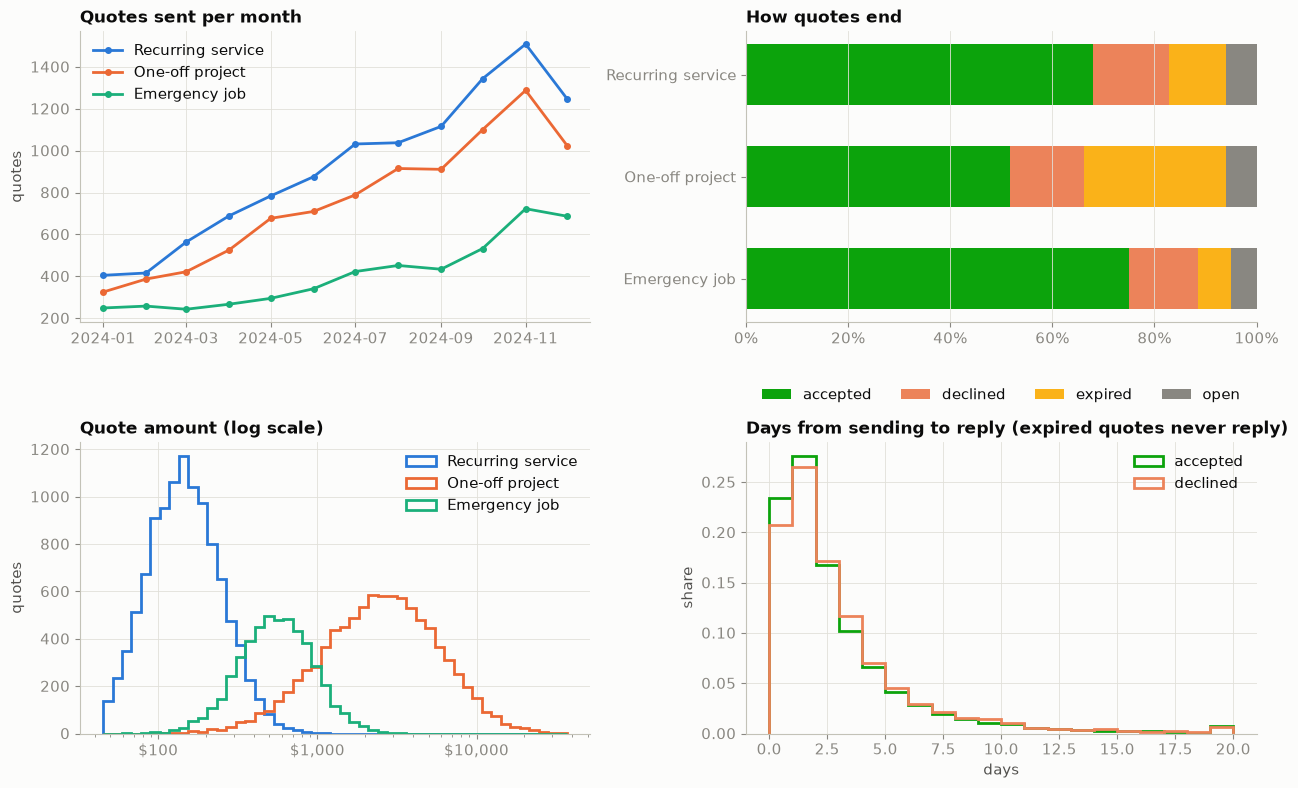

In [4]:
figures.eda_quotes(quotes)

- Volume roughly tripled during 2024 for every type of work.
- One-off projects end in silence far more often than other work.
- Amount mostly tracks type of work: recurring small, projects large.
- Yeses and nos arrive at similar speed, mostly within three days.

## 4. Acceptance by customer source and type of work

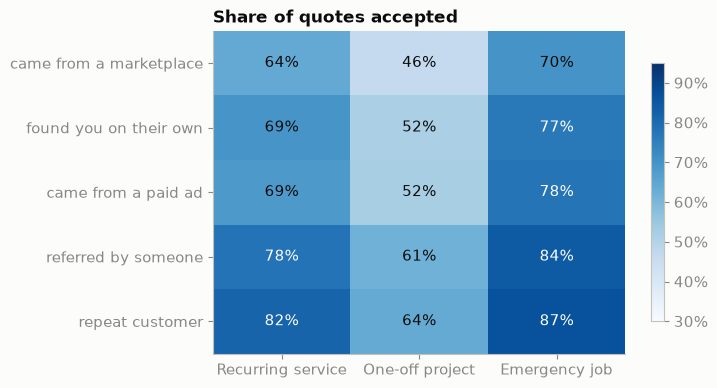

In [5]:
figures.eda_acceptance(quotes)

Customer source moves acceptance by 17 to 18 points within every type of work.

## 5. Reply timing (days from sending)

In [6]:
explore.reply_times(quotes)

,count,mean,std,min,25%,50%,75%,90%,max
status,,,,,,,,,
accepted,15863.0,2.70,3.45,0.04,1.04,1.38,3.29,6.21,45.38
declined,3630.0,2.88,3.47,0.04,1.08,2.08,3.38,6.33,45.08


Median 1.4 days to a yes, 2.1 to a no. Expired quotes never reply, so silence carries information.

## 6. Quotes waiting per business-morning (8am, Sep to Dec 2024)

median 2, max 21, business-mornings with 2+ waiting: 25,460


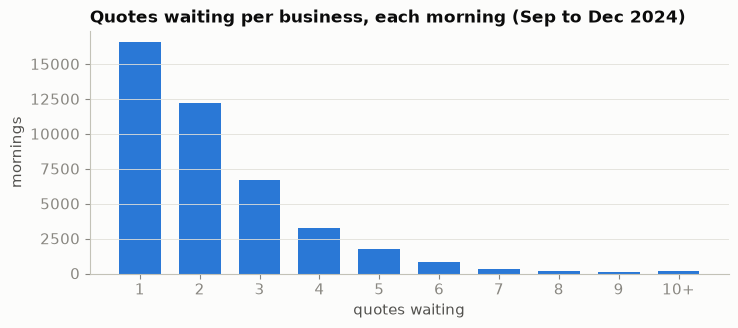

In [7]:
waiting = explore.waiting_per_morning(quotes, "2024-09-01", "2024-12-20")
print(
    f"median {waiting.median():.0f}, max {waiting.max()}, business-mornings with 2+ waiting: {(waiting >= 2).sum():,}"
)
figures.eda_waiting(waiting)

## 7. Variation between businesses

Actual wins per business against wins expected from its mix of work and customer sources.

In [8]:
explore.business_spread(quotes)

{'scatter compared with chance': 1.1, 'p-value': 0.061}

Scatter is close to chance, so no business-level term is needed. A typical business sends about 50 quotes a year.

## 8. Leads not pursued (scope and time)

In [9]:
explore.other_patterns(settings.data_dir, quotes)

,number
pattern,
accepted quotes that never became a job,"1,863 ($2.3M)"
completed jobs never invoiced,"1,991 ($2.6M planned)"
overdue invoices with no payment at all,"3,517 of 3,517 ($3.6M)"
failed payments that went through Jobber Payments,100%
"Jobber Payments failure rate, bank transfer vs card",38% vs 20%
failed payments whose invoice was paid later,100%
"visits cancelled: overall, after 3+ reschedules","10%, 21%"
quotes sent: January vs December 2024,"979 vs 2,958"
cancelled businesses still active afterwards,30 of 30
